# TechStream - Deteccion de anomalias en servidores (PyTorch)

**Objetivo:** entrenar una red neuronal densa (MLP) que, a partir de la telemetria de un servidor
(uso de CPU, uso de memoria, temperatura y trafico de red), prediga si el servidor va a **fallar** (1) o no (0).

Es un problema de **clasificacion binaria** sobre datos tabulares.

Pasos del notebook:
1. Imports y configuracion
2. Generacion / carga de los datos
3. Analisis exploratorio (EDA)
4. Preparacion de los datos (escalado + tensores + DataLoader)
5. Arquitectura de la red (clase `nn.Module`)
6. Funcion de perdida y optimizador
7. Bucle de entrenamiento
8. Evaluacion (precision, recall, matriz de confusion)
9. Guardar el modelo
10. Ejemplo de uso (inferencia)


## 1. Imports y configuracion

En Colab ya vienen instaladas todas estas librerias, no hace falta instalar nada.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

# Semilla para reproducibilidad (que los resultados sean repetibles)
SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# Seleccionamos el dispositivo: GPU si esta disponible, si no CPU.
# En PyTorch movemos a mano el modelo y los tensores a este device.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando device:", device)
print("Version de PyTorch:", torch.__version__)

Usando device: cuda
Version de PyTorch: 2.11.0+cu128


## 2. Carga de los datos


In [ ]:
df = pd.read_csv("data/server_telemetry.csv")
df.head()

,uso_cpu,uso_memoria,temperatura_cpu,trafico_red,fallo
0,49.96,53.70,59.11,451.81,0
1,55.26,62.76,56.36,419.75,0
2,53.68,56.47,57.59,581.83,1
3,40.21,62.84,50.53,360.37,0
4,55.94,59.37,63.66,591.84,1


## 3. Analisis exploratorio (EDA)

Antes de entrenar conviene **mirar los datos**: cuantas filas hay, como se distribuye la clase
(fallo / no fallo) y como se relacionan las variables entre si.

In [ ]:
print("Numero de filas y columnas:", df.shape)
print("\nEstadisticas basicas:")
df.describe()

Numero de filas y columnas: (6000, 5)

Estadisticas basicas:


,uso_cpu,uso_memoria,temperatura_cpu,trafico_red,fallo
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,47.986227,49.960385,54.122813,387.695820,0.220000
std,14.863263,12.088594,6.701980,203.621755,0.414281
min,9.610000,13.690000,34.160000,0.000000,0.000000
25%,36.790000,41.180000,49.310000,233.255000,0.000000
50%,46.850000,49.430000,53.715000,351.425000,0.000000
75%,58.407500,58.252500,58.730000,506.425000,0.000000
max,95.480000,91.910000,76.480000,1264.720000,1.000000


In [ ]:
# Reparto de la clase: cuantos fallos (1) y cuantos normales (0)
conteo = df["fallo"].value_counts()
print(conteo)
print("\nPorcentaje de fallos: {:.2f}%".format(df["fallo"].mean() * 100))

plt.figure(figsize=(5, 4))
sns.countplot(x="fallo", data=df)
plt.title("Reparto de clases (0 = normal, 1 = fallo)")
plt.show()

fallo
0    4680
1    1320
Name: count, dtype: int64

Porcentaje de fallos: 22.00%


C:\Users\gamba\AppData\Local\Temp\ipykernel_8608\1395383488.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Datos desbalanceados:** hay muchos mas casos normales que fallos (algo normal en deteccion de anomalias).
Esto es importante: si el modelo dijera siempre "no hay fallo" acertaria mucho en *accuracy* pero seria inutil.
Por eso mas adelante usaremos **precision y recall**, no solo la accuracy.

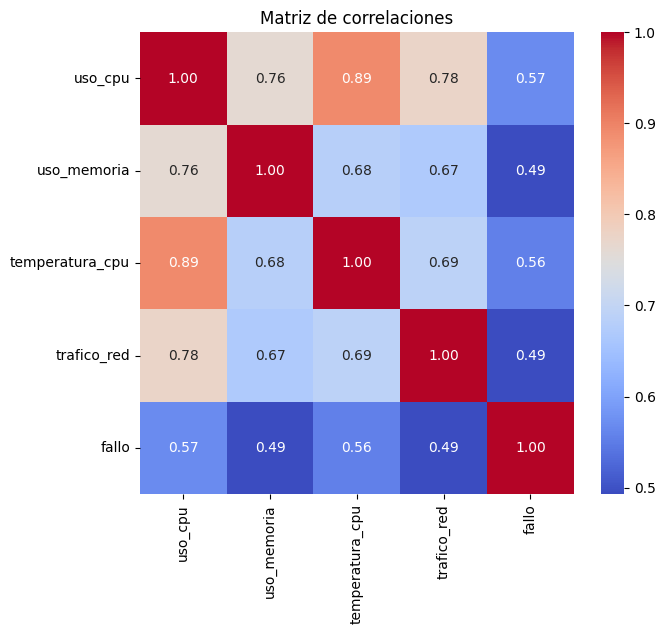

In [ ]:
# Matriz de correlaciones: que variables se mueven juntas
plt.figure(figsize=(7, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlaciones")
plt.show()

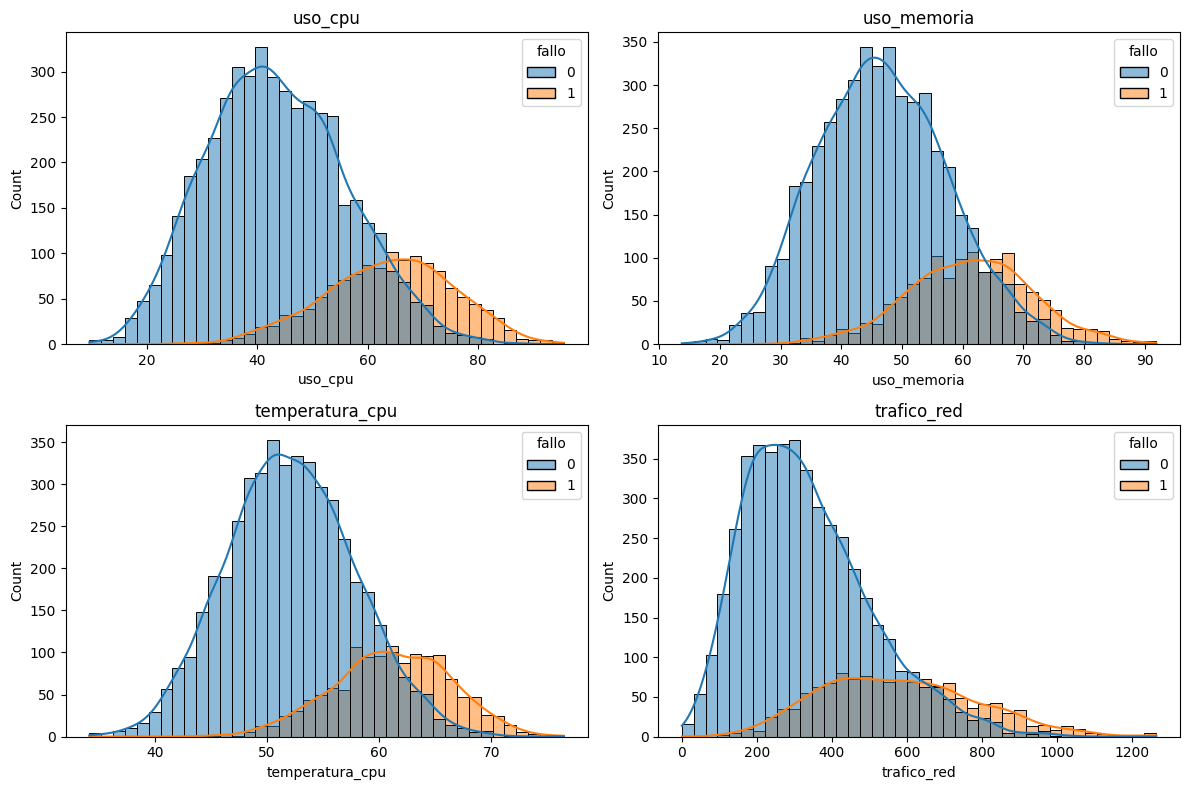

In [ ]:
# Histogramas de cada variable separando por clase (fallo vs normal)
variables = ["uso_cpu", "uso_memoria", "temperatura_cpu", "trafico_red"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), variables):
    sns.histplot(data=df, x=col, hue="fallo", bins=40, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Se ve que los servidores que **fallan** tienden a tener temperaturas y usos de CPU mas altos.
Hay solapamiento (por el ruido), asi que el problema no es trivial: por eso necesitamos la red neuronal.

## 4. Preparacion de los datos

Pasos:
1. Separar **X** (las 4 variables de entrada) de **y** (la etiqueta `fallo`).
2. Dividir en **train / validacion / test** de forma *estratificada* (manteniendo el % de fallos en cada parte).
3. **Escalar** las variables con `StandardScaler` (media 0, desviacion 1). Las redes aprenden mejor con datos escalados.
4. Convertir los arrays de NumPy en **tensores** de PyTorch y envolverlos en un `Dataset` y un `DataLoader`.

El `Dataset` sabe devolver una muestra (entrada, etiqueta) y el `DataLoader` agrupa las muestras
en lotes (batches) y las baraja en cada epoca.

In [ ]:
columnas_entrada = ["uso_cpu", "uso_memoria", "temperatura_cpu", "trafico_red"]
X = df[columnas_entrada].values        # matriz NumPy (6000, 4)
y = df["fallo"].values                 # vector NumPy (6000,)

# Primero separamos test (20%), luego del resto sacamos validacion (20% del 80% = 16%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, random_state=SEMILLA, stratify=y_temp)

print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)

Train: (3840, 4)  Val: (960, 4)  Test: (1200, 4)


In [ ]:
# Escalado: AJUSTAMOS el scaler SOLO con train y luego transformamos val y test.
# (Nunca se ajusta con test para no "hacer trampa" mirando datos futuros.)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Media tras escalar (train):", X_train.mean(axis=0).round(3))
print("Desviacion tras escalar (train):", X_train.std(axis=0).round(3))

Media tras escalar (train): [ 0. -0. -0. -0.]
Desviacion tras escalar (train): [1. 1. 1. 1.]


In [ ]:
# Dataset personalizado: convierte arrays NumPy en tensores y permite acceder muestra a muestra.
class TelemetryDataset(Dataset):
    def __init__(self, X, y):
        # float32 es el tipo estandar para las redes en PyTorch
        self.X = torch.tensor(X, dtype=torch.float32)
        # la etiqueta debe tener forma (N, 1) para encajar con la salida de la red
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.X)           # cuantas muestras hay

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]   # devuelve (entrada, etiqueta) de la posicion idx

train_ds = TelemetryDataset(X_train, y_train)
val_ds = TelemetryDataset(X_val, y_val)
test_ds = TelemetryDataset(X_test, y_test)

# El DataLoader agrupa las muestras en lotes (batches) y las baraja en cada epoca
BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

# Comprobamos como es un lote
xb, yb = next(iter(train_loader))
print("Forma de un lote de entradas:", xb.shape)   # (64, 4)
print("Forma de un lote de etiquetas:", yb.shape)  # (64, 1)

Forma de un lote de entradas: torch.Size([64, 4])
Forma de un lote de etiquetas: torch.Size([64, 1])


## 5. Arquitectura de la red: la clase `AnomalyMLP`

El modelo se define como una **clase** que hereda de `nn.Module`. Tiene dos partes:
- `__init__`: definimos las capas (las piezas de la red).
- `forward`: definimos como fluyen los datos por esas capas (el "camino" de la entrada a la salida).

La red: `4 entradas -> 64 -> 32 -> 1 salida`. Usamos ReLU como activacion y Dropout para evitar el sobreajuste.

**Detalle importante:** la ultima capa devuelve un **logit** (un numero sin acotar), NO una probabilidad.
No ponemos sigmoide al final porque la funcion de perdida que usaremos (`BCEWithLogitsLoss`) ya la aplica
internamente de forma mas estable numericamente.

In [ ]:
class AnomalyMLP(nn.Module):
    def __init__(self, n_entradas, n_oculta1=64, n_oculta2=32, p_dropout=0.3):
        super().__init__()   # obligatorio: inicializa la clase base nn.Module

        # nn.Sequential apila las capas en orden
        self.red = nn.Sequential(
            nn.Linear(n_entradas, n_oculta1),  # capa densa (totalmente conectada)
            nn.ReLU(),                          # activacion
            nn.Dropout(p_dropout),              # apaga aleatoriamente neuronas (regularizacion)

            nn.Linear(n_oculta1, n_oculta2),
            nn.ReLU(),
            nn.Dropout(p_dropout),

            nn.Linear(n_oculta2, 1),            # capa de salida: 1 numero (logit)
        )

    def forward(self, x):
        # Define como pasan los datos por la red. Devuelve logits (sin sigmoide).
        return self.red(x)

# Creamos el modelo y lo movemos al device (CPU o GPU)
modelo = AnomalyMLP(n_entradas=len(columnas_entrada)).to(device)
print(modelo)

AnomalyMLP(
  (red): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 6. Funcion de perdida y optimizador

Definimos dos objetos que guiaran el entrenamiento:

- **Perdida (loss):** `BCEWithLogitsLoss`. Es la *Binary Cross Entropy* combinada con la sigmoide
  en un solo paso, lo que es mas estable numericamente. Como tenemos pocos fallos, usamos `pos_weight`
  para que el modelo **preste mas atencion a la clase minoritaria** (los fallos).
- **Optimizador:** `Adam`, que ajusta los pesos de la red para reducir la perdida.

In [ ]:
# pos_weight = (nº de negativos) / (nº de positivos). Pesa mas los fallos al calcular el error.
n_negativos = (y_train == 0).sum()
n_positivos = (y_train == 1).sum()
pos_weight = torch.tensor([n_negativos / n_positivos], dtype=torch.float32, device=device)
print("pos_weight:", pos_weight.item())

criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

pos_weight: 3.5443787574768066


## 7. Bucle de entrenamiento

En PyTorch **escribimos el bucle de entrenamiento a mano**, de modo que se ve claramente
que ocurre en cada paso:

1. `optimizador.zero_grad()` -> borra los gradientes del paso anterior.
2. `logits = modelo(xb)` -> pasada hacia delante (forward).
3. `loss = criterio(logits, yb)` -> calcula el error.
4. `loss.backward()` -> calcula los gradientes (backpropagation).
5. `optimizador.step()` -> actualiza los pesos.

Repetimos esto para cada lote, en cada **epoca**. Tambien medimos la perdida de validacion para vigilar el sobreajuste.

In [ ]:
def evaluar_perdida(modelo, loader):
    """Calcula la perdida media en un loader sin entrenar (modo evaluacion)."""
    modelo.eval()                      # desactiva Dropout
    total, n = 0.0, 0
    with torch.no_grad():              # no calculamos gradientes -> mas rapido
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo(xb)
            total += criterio(logits, yb).item() * len(xb)
            n += len(xb)
    return total / n

EPOCAS = 60
hist_train, hist_val = [], []

for epoca in range(EPOCAS):
    modelo.train()                     # modo entrenamiento (Dropout activo)
    perdida_acum, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)   # movemos el lote al device

        optimizador.zero_grad()        # 1. borrar gradientes
        logits = modelo(xb)            # 2. forward
        loss = criterio(logits, yb)    # 3. calcular error
        loss.backward()                # 4. backpropagation
        optimizador.step()             # 5. actualizar pesos

        perdida_acum += loss.item() * len(xb)
        n += len(xb)

    perdida_train = perdida_acum / n
    perdida_val = evaluar_perdida(modelo, val_loader)
    hist_train.append(perdida_train)
    hist_val.append(perdida_val)

    if (epoca + 1) % 10 == 0 or epoca == 0:
        print(f"Epoca {epoca+1:3d}/{EPOCAS} - perdida train: {perdida_train:.4f} - perdida val: {perdida_val:.4f}")

Epoca   1/60 - perdida train: 0.8313 - perdida val: 0.6828
Epoca  10/60 - perdida train: 0.6271 - perdida val: 0.6751
Epoca  20/60 - perdida train: 0.6263 - perdida val: 0.6824
Epoca  30/60 - perdida train: 0.6201 - perdida val: 0.6837
Epoca  40/60 - perdida train: 0.6245 - perdida val: 0.6899
Epoca  50/60 - perdida train: 0.6285 - perdida val: 0.6838
Epoca  60/60 - perdida train: 0.6168 - perdida val: 0.6863


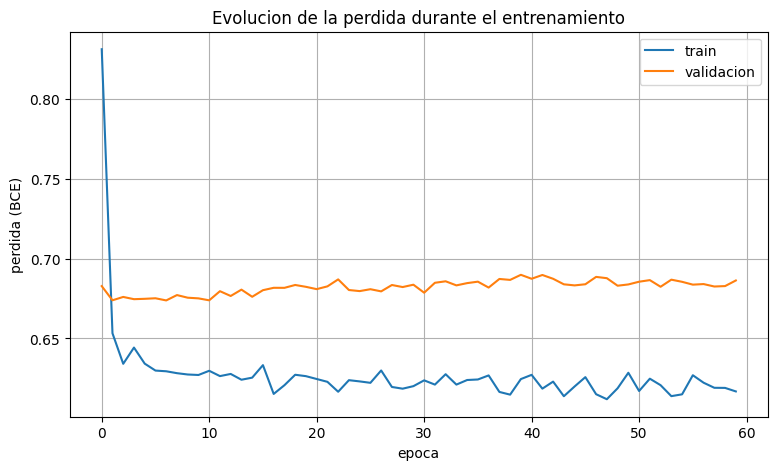

In [ ]:
# Curvas de perdida: nos dicen si el modelo aprende y si se sobreajusta
plt.figure(figsize=(9, 5))
plt.plot(hist_train, label="train")
plt.plot(hist_val, label="validacion")
plt.xlabel("epoca")
plt.ylabel("perdida (BCE)")
plt.title("Evolucion de la perdida durante el entrenamiento")
plt.legend()
plt.grid(True)
plt.show()

## 8. Evaluacion: precision, recall y matriz de confusion

Ahora medimos como de bien funciona el modelo con el conjunto de **test** (datos que nunca ha visto).

- La red devuelve **logits**; les aplicamos la **sigmoide** para obtener probabilidades (0 a 1).
- Si la probabilidad >= 0.5 -> predecimos **fallo** (1).
- Comparamos con la realidad y calculamos las metricas.

Calculamos la **matriz de confusion a mano** (para ver el manejo de tensores) y tambien con sklearn para verificar.

In [ ]:
modelo.eval()
X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)

with torch.no_grad():
    logits_test = modelo(X_test_t)            # logits
    probs_test = torch.sigmoid(logits_test)   # probabilidades
    pred_test = (probs_test >= 0.5).int()      # 0 o 1

# Pasamos a NumPy (en CPU) para comparar
probs_np = probs_test.cpu().numpy().ravel()
pred_np = pred_test.cpu().numpy().ravel()

# --- Matriz de confusion calculada A MANO con operaciones de tensores/arrays ---
y_real = y_test
TP = int(((pred_np == 1) & (y_real == 1)).sum())   # fallo predicho y real
TN = int(((pred_np == 0) & (y_real == 0)).sum())   # normal predicho y real
FP = int(((pred_np == 1) & (y_real == 0)).sum())   # dijo fallo pero era normal (falsa alarma)
FN = int(((pred_np == 0) & (y_real == 1)).sum())   # dijo normal pero era fallo (fallo no detectado)

print("Calculo manual:")
print(f"  Verdaderos Positivos (TP): {TP}")
print(f"  Verdaderos Negativos (TN): {TN}")
print(f"  Falsos Positivos (FP):     {FP}")
print(f"  Falsos Negativos (FN):     {FN}")

precision_manual = TP / (TP + FP) if (TP + FP) > 0 else 0
recall_manual = TP / (TP + FN) if (TP + FN) > 0 else 0
print(f"\n  Precision (manual): {precision_manual:.3f}")
print(f"  Recall    (manual): {recall_manual:.3f}")

Calculo manual:
  Verdaderos Positivos (TP): 203
  Verdaderos Negativos (TN): 748
  Falsos Positivos (FP):     188
  Falsos Negativos (FN):     61

  Precision (manual): 0.519
  Recall    (manual): 0.769


In [ ]:
# --- Verificacion con sklearn ---
print("Precision:", round(precision_score(y_test, pred_np), 3))
print("Recall:   ", round(recall_score(y_test, pred_np), 3))
print("F1-score: ", round(f1_score(y_test, pred_np), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, probs_np), 3))

Precision: 0.519
Recall:    0.769
F1-score:  0.62
ROC-AUC:   0.87


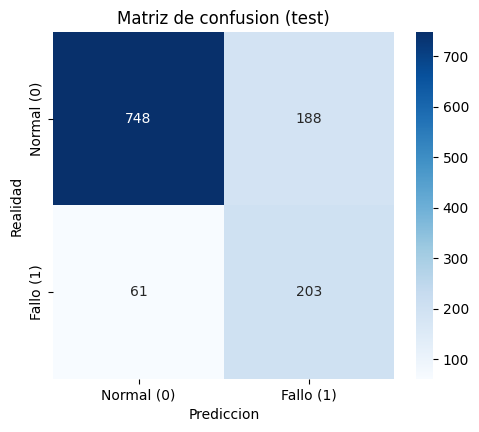

In [ ]:
# Matriz de confusion visual
cm = confusion_matrix(y_test, pred_np)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal (0)", "Fallo (1)"],
            yticklabels=["Normal (0)", "Fallo (1)"])
plt.xlabel("Prediccion")
plt.ylabel("Realidad")
plt.title("Matriz de confusion (test)")
plt.show()

**Como leer las metricas en este problema:**
- **Recall** (sensibilidad): de todos los fallos reales, cuantos detectamos. Es lo MAS importante aqui:
  no queremos que un servidor se caiga sin avisar.
- **Precision:** de todas las alarmas que damos, cuantas eran fallos de verdad. Si es baja, generamos falsas alarmas.
- El **umbral 0.5** se puede bajar (p.ej. 0.3) para detectar mas fallos a costa de mas falsas alarmas.

## 9. Guardar el modelo entrenado

En PyTorch lo habitual es guardar el `state_dict` (los pesos aprendidos). Guardamos tambien los
parametros del `scaler` y la configuracion de la red, porque para usar el modelo mas adelante
necesitaremos escalar las nuevas lecturas igual que en el entrenamiento.

In [ ]:
import os
os.makedirs("modelo", exist_ok=True)
ruta_modelo = "modelo/anomaly_mlp.pt"

torch.save({
    "model_state": modelo.state_dict(),
    "config": {"n_entradas": len(columnas_entrada), "n_oculta1": 64, "n_oculta2": 32},
    "columnas_entrada": columnas_entrada,
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_,
}, ruta_modelo)

print("Modelo guardado en:", ruta_modelo)

# En Colab, descarga el fichero a tu ordenador (descomenta si lo necesitas):
# from google.colab import files
# files.download(ruta_modelo)

Modelo guardado en: modelo/anomaly_mlp.pt


## 10. Ejemplo de uso (inferencia)

Asi se usaria el modelo en produccion: llega una lectura nueva de un servidor y, a partir de su
telemetria, el modelo estima la probabilidad de fallo.

In [ ]:
def predecir(lectura, modelo, scaler, columnas, umbral=0.5):
    """lectura: dict con uso_cpu, uso_memoria, temperatura_cpu, trafico_red."""
    # 1. Ordenamos los valores como en el entrenamiento y escalamos
    x = np.array([[lectura[c] for c in columnas]], dtype=np.float32)
    x = (x - scaler.mean_) / scaler.scale_       # mismo escalado que en train

    # 2. Tensor -> modelo -> probabilidad
    x_t = torch.tensor(x, dtype=torch.float32).to(device)
    modelo.eval()
    with torch.no_grad():
        prob = torch.sigmoid(modelo(x_t)).item()

    veredicto = "FALLO" if prob >= umbral else "OK"
    return prob, veredicto

# Caso 1: servidor tranquilo -> deberia dar OK
servidor_ok = {"uso_cpu": 30, "uso_memoria": 40, "temperatura_cpu": 48, "trafico_red": 200}
prob, veredicto = predecir(servidor_ok, modelo, scaler, columnas_entrada)
print(f"Servidor tranquilo  -> prob fallo = {prob:.2%} -> {veredicto}")

# Caso 2: servidor al limite -> deberia dar FALLO
servidor_critico = {"uso_cpu": 95, "uso_memoria": 90, "temperatura_cpu": 88, "trafico_red": 1500}
prob, veredicto = predecir(servidor_critico, modelo, scaler, columnas_entrada)
print(f"Servidor al limite  -> prob fallo = {prob:.2%} -> {veredicto}")

Servidor tranquilo  -> prob fallo = 1.57% -> OK
Servidor al limite  -> prob fallo = 99.96% -> FALLO


## Conclusiones

- Hemos construido de cero, en PyTorch, un detector de anomalias para servidores.
- Hemos implementado las piezas clave a mano: la **clase del modelo** (`nn.Module`),
  el manejo de **tensores** (`Dataset`/`DataLoader`, `device`, `float32`) y el **bucle de entrenamiento** manual.
- El modelo detecta los fallos con buen recall, que es lo critico en este caso de uso.

Posibles mejoras: ajustar el umbral de decision, probar mas capas/neuronas, o tratar la telemetria
como serie temporal con una **LSTM** si tuvieramos secuencias en el tiempo.